# Step 1：带间隙约束的需求加权部署

按 **研究问题 → 方法 → 评价 → 优化参照 → 结果 → 局限** 阅读已经保存的结果。核心计算在 `src/udc/`，这里只调用包内函数并读取轨迹。

## 研究问题

在固定 Guide 数量下，怎样提高热点一侧的需求覆盖，同时保持最大弧间隙、最小间距和可达性。人员权重均匀并不使 Gaussian 曲线密度均匀。上一轮凸曲线上，浓度调节没有触发，因此当前要评价的是间隙投影本身。

## 方法

`projected_mass` 是带覆盖间隙约束的需求加权边界部署：在原始需求密度上做周期 CVT，每一步把弧间隙投影到 $[d_{\min}, H_p]$，并保留整体相位。RA-ABDC 使用同一次投影；只有欧氏间距仍然失败时才减半浓度。那一步在已有实验里没有发生。

数值参照用同一目标和同一积分，从 Equal Arc 与 `projected_mass` 出发做 SLSQP。它只产生目标位置，不是完整任务的最优解。

## 评价

全曲线代价是原始 Gaussian 需求下的均方弧长距离，单位 m²，越小越好。热点超额是冻结需求减去背景，核与带宽不变。局部超额达到该点需求一半的弧段不依赖 Guide。没有超额时，热点指标不适用。目标位置和实际位置分开。实际点离开曲线超过容差时单独标记，不用投影把偏离藏起来。

uniform not applicable 30
projected minus equal {'n': 90, 'mean': -0.0051322854842013755, 'min': -0.02597028876921023, 'max': -0.00025683395365425077}
rescued ratio of means 0.4014799140637096


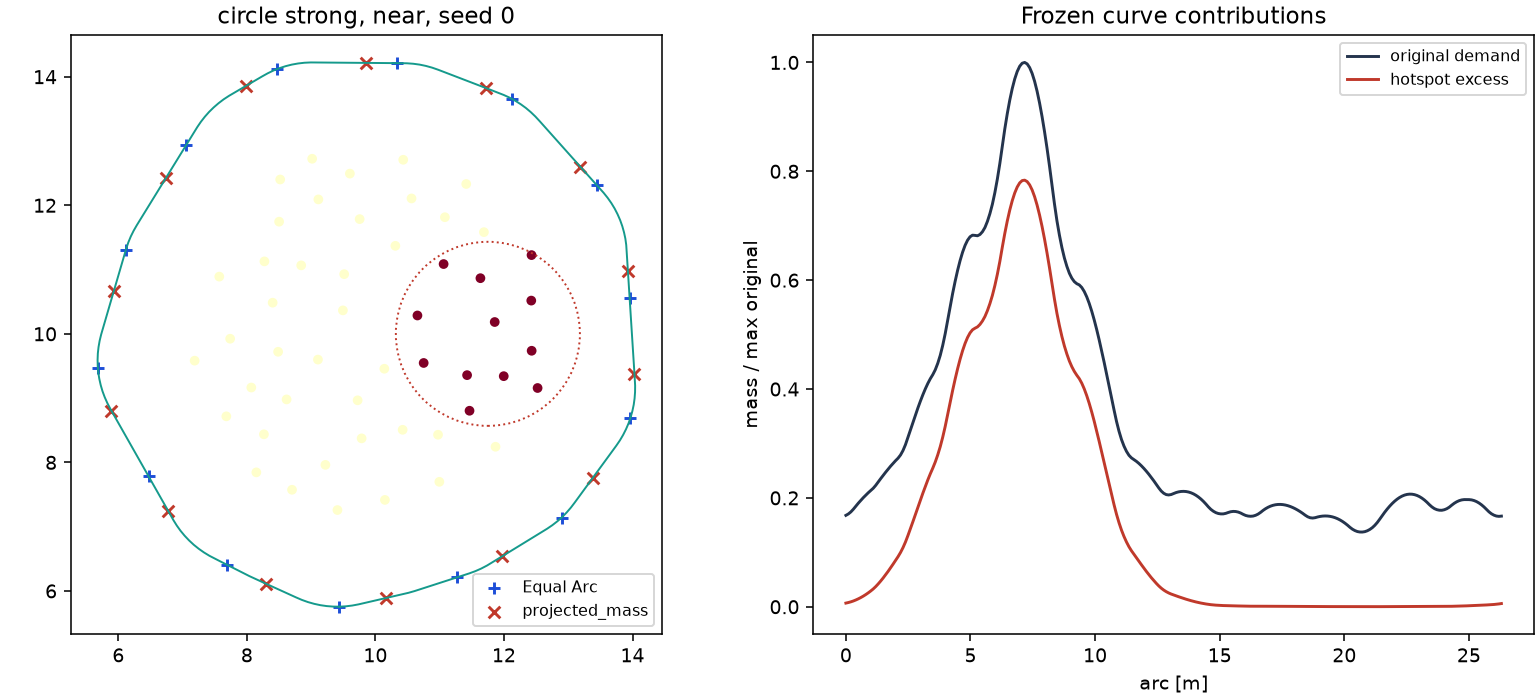

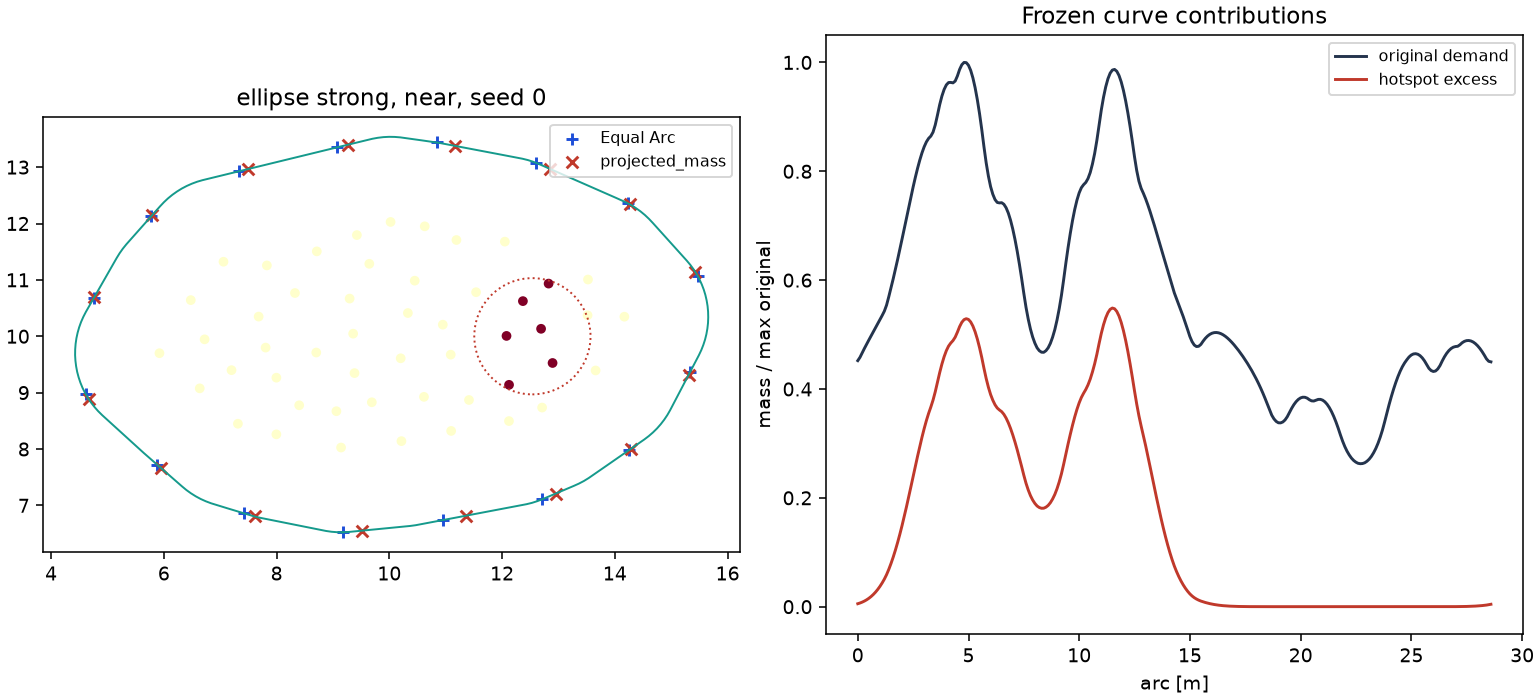

In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

from udc.analysis.reanalysis import reanalyze

ROOT = Path.cwd() if (Path.cwd() / 'src' / 'udc').exists() else Path.cwd().parent
summary_path = ROOT / 'runs' / 'reproduction' / 'Kaii' / 'phase_e' / 'excess_reanalysis' / 'excess_summary.json'
if not summary_path.exists():
    reanalyze(ROOT / 'runs' / 'reproduction' / 'Kaii' / 'phase_d' / 'projection_matrix' / 'comparison.json',
              ROOT / 'runs' / 'reproduction' / 'Kaii' / 'phase_e' / 'excess_reanalysis')
summary = json.loads(summary_path.read_text(encoding='utf-8'))
print('uniform not applicable', summary['uniform_marked_not_applicable'])
print('projected minus equal', summary['projected_minus_equal_demand_cost'])
print('rescued ratio of means', summary['rescued']['demand_retention_ratio_of_means'])
for name in ('circle_strong_near_seed0.png', 'ellipse_strong_near_seed0.png'):
    display(Image(filename=str(ROOT / 'runs' / 'reproduction' / 'Kaii' / 'phase_e' / 'excess_reanalysis' / 'figures' / name)))

## 优化参照

12 个贴近数量下界的场景只做规划比较。新设备结果在 `runs/reproduction/Kaii/phase_e/reference` 和 `reference_sensitivity`。参照相对 `projected_mass` 的改进约为 0.00020–0.00527 m²。圆形强热点大约 0.004–0.0046 m²。椭圆强热点 seed 0 是 0.00157 m²，大于旧设备文字里的 0.0004 m²。积分点从 1024 增到 4096 时，圆形强热点 seed 0 的改进仍是 0.00402、0.00406、0.00409。

## 结果

90 对里，`projected_mass` 的全曲线规划代价都低于 Equal Arc，均值差 −0.00513 m²。Mass CVT 已经可行的 62 对上，二者几乎相同。28 个原先不可行的任务被投影修复；三个规划代价的均值是 0.275789、0.282797、0.287497，投影留下约 40.1% 的无约束代价改进。这只描述这 28 个任务，不是全体任务的性能涨幅。

多初值参照能再降一点代价，尤其是圆形强热点，但没有找到另一类明显更好的可行方案。若干次迭代达到上限，独立检查仍然可行；上限用尽不是不可行。

## 正式验证

种子 5000–5029 的 1620 个任务与上面的开发重跑分开。Equal Arc 和 `projected_mass` 都是 540/540。Mass CVT 是 377/540，163 次失败都是规划搜索耗尽，投影后都通过验收。没有指派失败或执行失败。

540 对规划需求代价都低于 Equal Arc。种子均值差 −0.00493 m²，95% 区间 [−0.00521, −0.00467]。逐对相对差的均值是 −2.47%，总体均值之比是 −2.30%。这是较小的覆盖收益，不是成功率优势。强热点超额代价全部更低；180 个弱热点里有 11 对超额代价略高。背景代价的种子均值高 0.00110 m²。路径平均长 0.324 m，部署时间平均多 0.035 s，规划时间平均多 0.047 s。实际最大间隙平均从 1.590 m 增到 1.746 m，仍通过原有验收。

图在 `runs/formal/step1_projection_v1/figures/`。中位配对和最差配对都是圆形、弱热点、N=14，种子分别是 5010 和 5023。没有 Equal Arc 成功而 `projected_mass` 失败的单元。

In [ ]:
formal = json.loads((ROOT / 'runs' / 'formal' / 'step1_projection_v1' / 'formal_report.json').read_text(encoding='utf-8'))
paired = formal['overall']['paired']['projected_mass']['planned_demand_weighted_cost']
print(formal['slice_counts'])
print(paired['seed_cluster'])
for name in ('success_stages.png', 'demand_cost_deltas.png', 'hotspot_background.png', 'cost_of_deployment.png'):
    display(Image(filename=str(ROOT / 'runs' / 'formal' / 'step1_projection_v1' / 'figures' / name)))

## 局限

数量界只在“目标位于这一条曲线、弦长不超过弧长”时是必要条件。投影保证的是弧间隙盒子里的数值可行点，不保证原始目标下降、全局最优或欧氏间距。可达和执行安全仍由原有导航与线段复核负责。浓度调节没有被检验。

正式结果仍限于一个静态人群、凸部署曲线、已知场地和全局观测。需求是规划权重。旧设备数值参照里椭圆强热点 seed 0 的连续量差异留在记录中，没有为追平它而改预算。